# 05 · Exploratory Data Analysis (EDA)
**CIS 517 – Hotel Booking Cancellation Prediction Using Data Mining**

Goal: explore the cleaned data visually before modelling. Each chart answers one question:
how the main attributes are distributed, which attributes are related to cancellation,
how prices change over the year, and which attributes are correlated.
All charts are saved to `figures/` for the report and the website.

ــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــ

### 1. Setup
One consistent chart style for the whole project, using the website colors (blue, cyan, green).

In [9]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/hotel_bookings_clean.csv", parse_dates=["arrival_date"])
print("Data:", df.shape)

BLUE, CYAN, GREEN, ORANGE = "#2563eb", "#06b6d4", "#10b981", "#f97316"
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
})

FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

Data: (86637, 41)


### 2. Distribution of the main numeric attributes
**Question:** what do typical bookings look like (how far in advance, at what price, for how long)?
The dashed line marks the median.

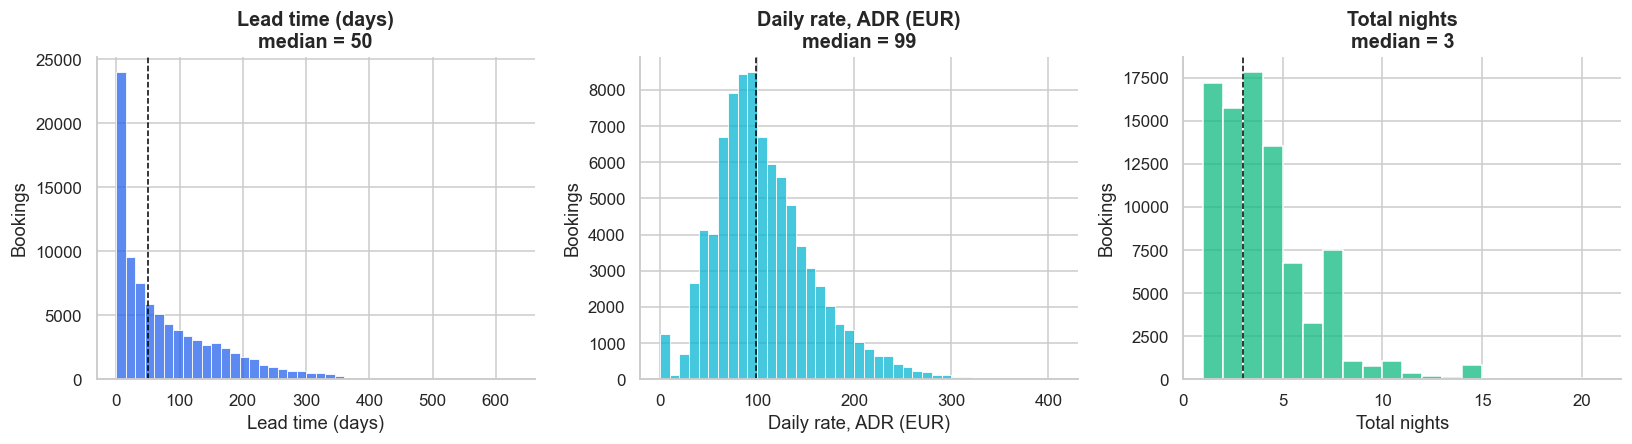

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

specs = [
    ("lead_time", "Lead time (days)", range(0, 640, 15), BLUE),
    ("adr", "Daily rate, ADR (EUR)", range(0, 420, 10), CYAN),
    ("total_nights", "Total nights", range(1, 22), GREEN),
]

for ax, (col, label, bins, color) in zip(axes, specs):
    sns.histplot(df[col], bins=list(bins), color=color, ax=ax)
    median = df[col].median()
    ax.axvline(median, color="black", linestyle="--", linewidth=1)
    ax.set_title(f"{label}\nmedian = {median:g}")
    ax.set_xlabel(label)
    ax.set_ylabel("Bookings")

fig.tight_layout()
save(fig, "eda_01_distributions")
plt.show()

### 3. Cancellation rate by attribute
**Question:** which attributes are related to cancellation?
Each bar is the share of canceled bookings in that group; the dashed line is the overall rate (27.7%).
Large differences between groups suggest the attribute will be useful for classification.

/var/folders/0q/rfm3_3d52276fwzmptbxykxh0000gn/T/ipykernel_6836/518259945.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rates = data.groupby(col)["is_canceled"].agg(["mean", "size"])


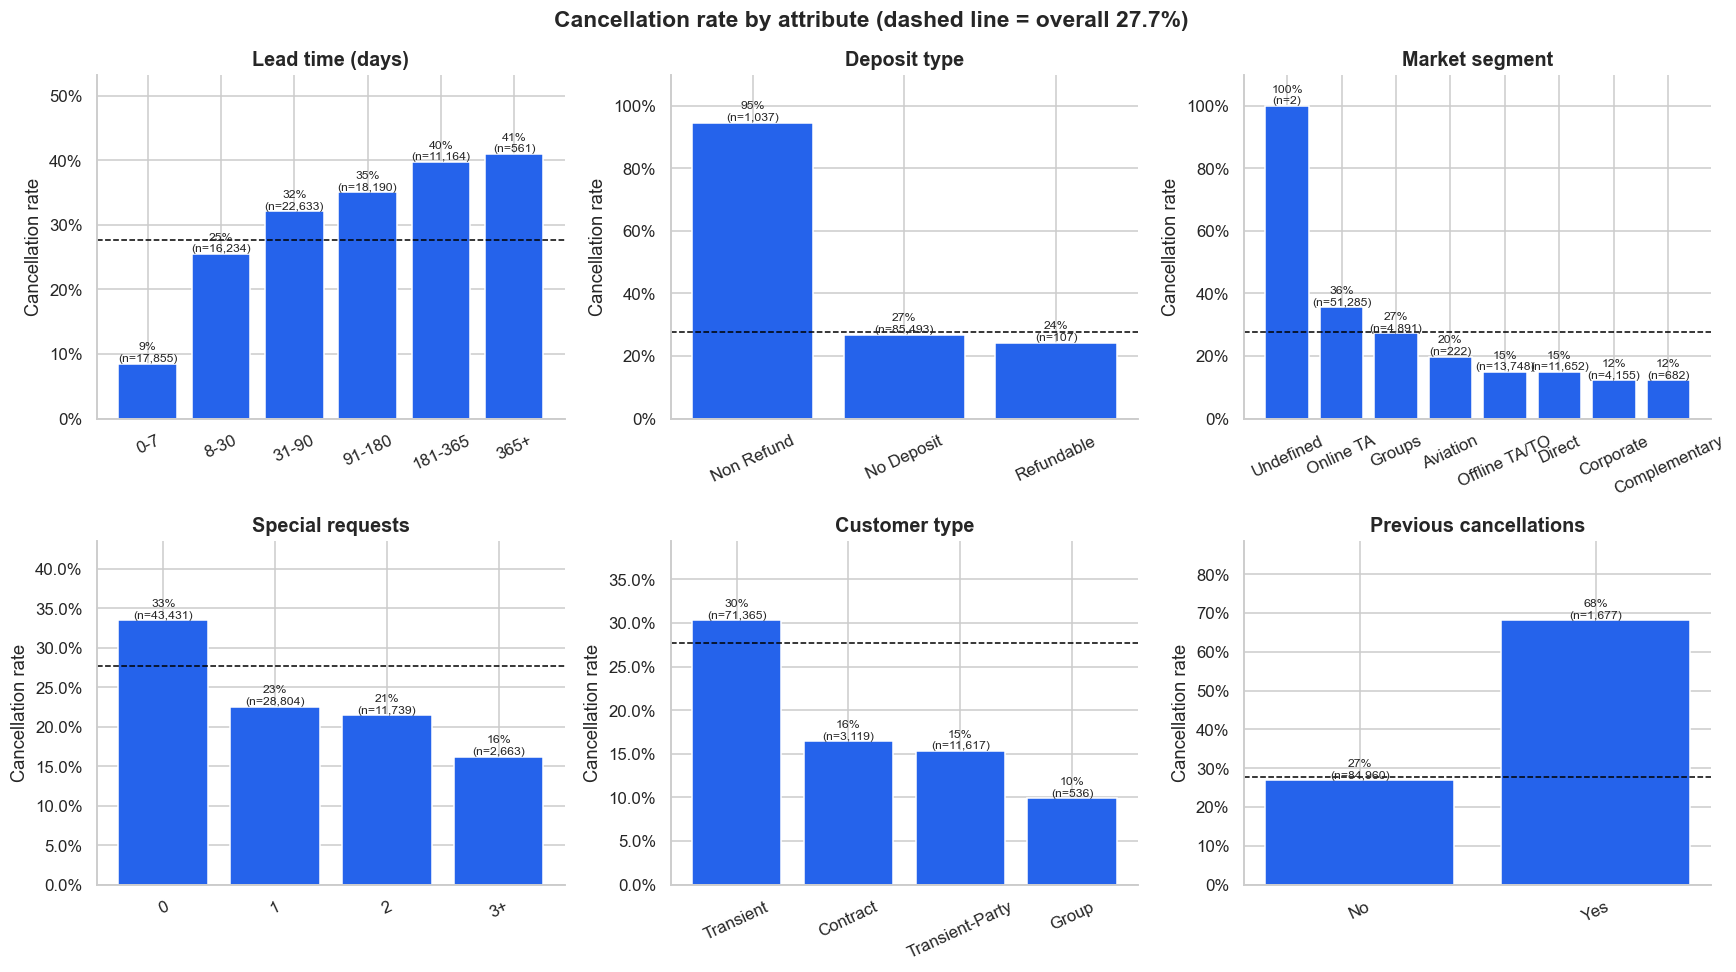

In [11]:
overall = df["is_canceled"].mean()

def cancel_rate_plot(ax, data, col, title, order=None):
    rates = data.groupby(col)["is_canceled"].agg(["mean", "size"])
    rates = rates.loc[order] if order else rates.sort_values("mean", ascending=False)
    bars = ax.bar(rates.index.astype(str), rates["mean"], color=BLUE)
    ax.axhline(overall, color="black", linestyle="--", linewidth=1)
    for bar, (rate, n) in zip(bars, rates.values):
        ax.annotate(f"{rate:.0%}\n(n={int(n):,})", (bar.get_x() + bar.get_width() / 2, rate),
                    ha="center", va="bottom", fontsize=8)
    ax.set_title(title)
    ax.set_ylabel("Cancellation rate")
    ax.set_ylim(0, min(1.1, rates["mean"].max() * 1.3))
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    ax.tick_params(axis="x", rotation=25)

plot_df = df.assign(
    lead_group=pd.cut(df["lead_time"], [-1, 7, 30, 90, 180, 365, 1000],
                      labels=["0-7", "8-30", "31-90", "91-180", "181-365", "365+"]),
    requests=df["total_of_special_requests"].clip(upper=3).astype(str).replace("3", "3+"),
    previous_cancel=np.where(df["previous_cancellations"] > 0, "Yes", "No"),
)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
cancel_rate_plot(axes[0, 0], plot_df, "lead_group", "Lead time (days)",
                 order=["0-7", "8-30", "31-90", "91-180", "181-365", "365+"])
cancel_rate_plot(axes[0, 1], plot_df, "deposit_type", "Deposit type")
cancel_rate_plot(axes[0, 2], plot_df, "market_segment", "Market segment")
cancel_rate_plot(axes[1, 0], plot_df, "requests", "Special requests", order=["0", "1", "2", "3+"])
cancel_rate_plot(axes[1, 1], plot_df, "customer_type", "Customer type")
cancel_rate_plot(axes[1, 2], plot_df, "previous_cancel", "Previous cancellations", order=["No", "Yes"])

fig.suptitle("Cancellation rate by attribute (dashed line = overall 27.7%)", fontsize=15, fontweight="bold")
fig.tight_layout()
save(fig, "eda_02_cancel_rate_by_attribute")
plt.show()

### 4. Seasonality
**Question:** how do the number of bookings, the price and the cancellation rate change over the year, and do the two hotels behave the same way?

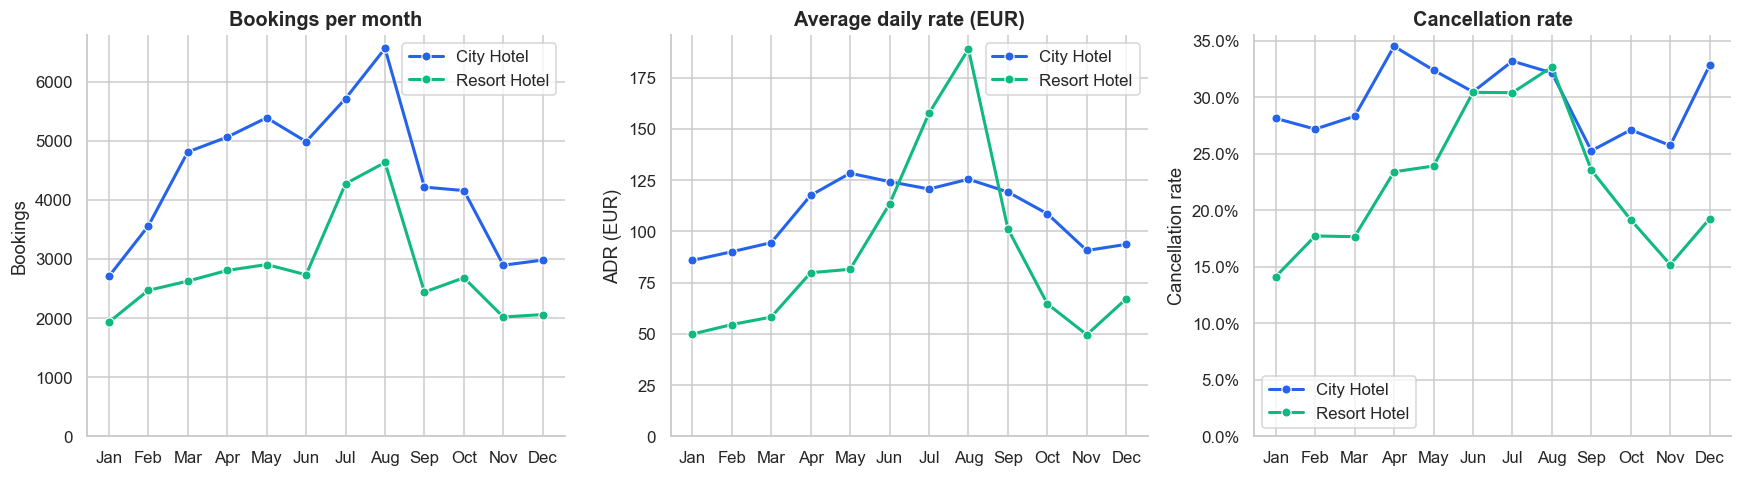

In [12]:
monthly = (df.groupby(["arrival_month_num", "hotel"])
             .agg(bookings=("is_canceled", "size"),
                  adr=("adr", "mean"),
                  cancel_rate=("is_canceled", "mean"))
             .reset_index())

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
hotel_colors = {"City Hotel": BLUE, "Resort Hotel": GREEN}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
panels = [("bookings", "Bookings per month", "Bookings"),
          ("adr", "Average daily rate (EUR)", "ADR (EUR)"),
          ("cancel_rate", "Cancellation rate", "Cancellation rate")]

for ax, (col, title, ylabel) in zip(axes, panels):
    sns.lineplot(data=monthly, x="arrival_month_num", y=col, hue="hotel",
                 palette=hotel_colors, marker="o", linewidth=2, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(month_names)
    ax.legend(title="")
    ax.set_ylim(bottom=0)

axes[2].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
fig.tight_layout()
save(fig, "eda_03_seasonality")
plt.show()

### 5. Price distribution by hotel
**Question:** how do prices differ between the two hotels, and are there extreme values?

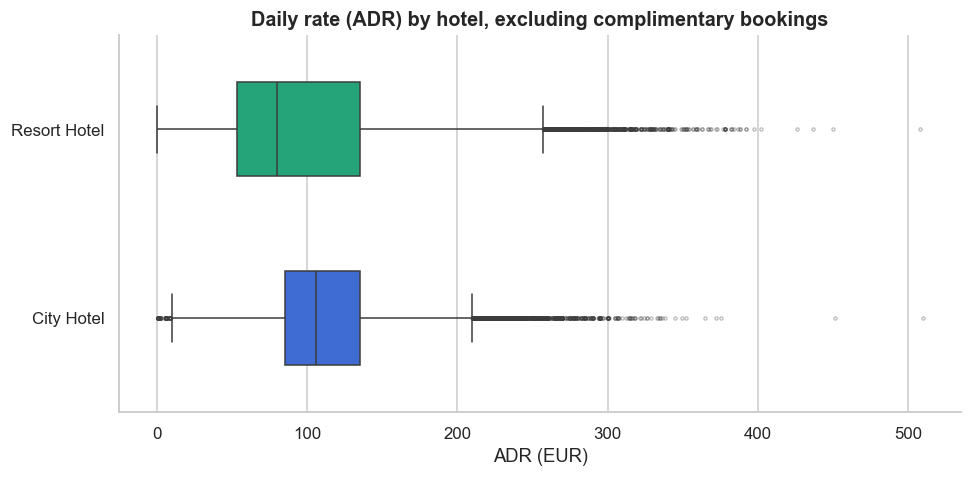

,count,mean,std,min,25%,50%,75%,max
hotel,,,,,,,,
City Hotel,52320.0,113.2,39.5,0.5,85.0,106.2,135.0,510.0
Resort Hotel,33265.0,101.1,62.8,0.3,53.4,80.1,135.0,508.0


In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=df[df["adr"] > 0], x="adr", y="hotel", hue="hotel",
            palette=hotel_colors, legend=False, width=0.5, ax=ax,
            flierprops={"marker": "o", "markersize": 2, "alpha": 0.3})
ax.set_title("Daily rate (ADR) by hotel, excluding complimentary bookings")
ax.set_xlabel("ADR (EUR)")
ax.set_ylabel("")
fig.tight_layout()
save(fig, "eda_04_adr_boxplot")
plt.show()

df[df["adr"] > 0].groupby("hotel")["adr"].describe().round(1)

### 6. Lead time vs. price
**Question:** can canceled and kept bookings be separated using just two attributes?
A random sample of 3,000 bookings is plotted so that the points do not hide each other.

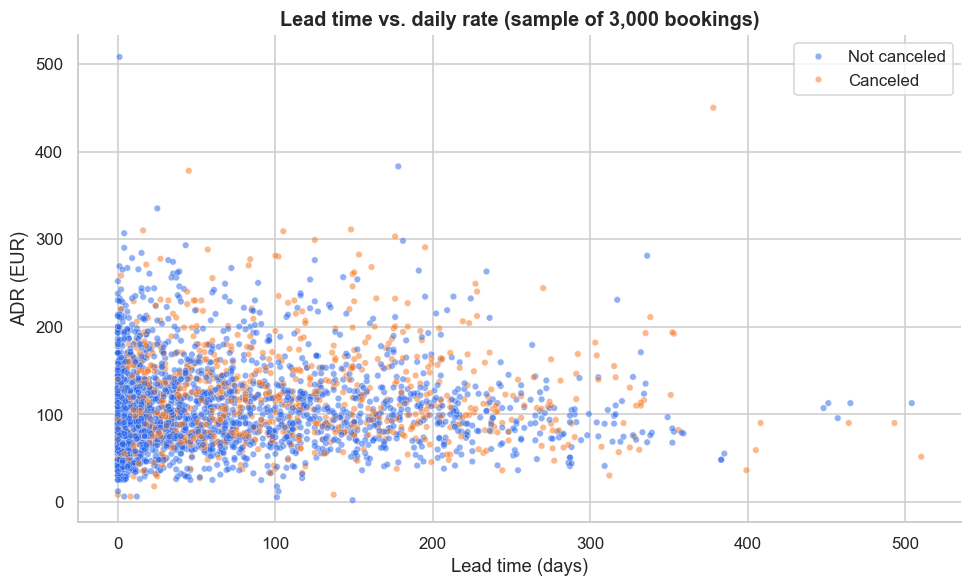

Correlation lead_time vs adr: 0.04


In [14]:
sample = df[df["adr"] > 0].sample(3000, random_state=42)

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(data=sample, x="lead_time", y="adr", hue="is_canceled",
                palette={0: BLUE, 1: ORANGE}, alpha=0.5, s=18, ax=ax)
ax.set_title("Lead time vs. daily rate (sample of 3,000 bookings)")
ax.set_xlabel("Lead time (days)")
ax.set_ylabel("ADR (EUR)")
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["Not canceled", "Canceled"], title="")
fig.tight_layout()
save(fig, "eda_05_scatter_lead_adr")
plt.show()

print(f"Correlation lead_time vs adr: {sample['lead_time'].corr(sample['adr']):.2f}")

### 7. Correlation matrix
**Question:** which numeric attributes move together, and which are linearly related to cancellation?
Pearson correlation ranges from −1 (opposite direction) to +1 (same direction); 0 means no linear relation.

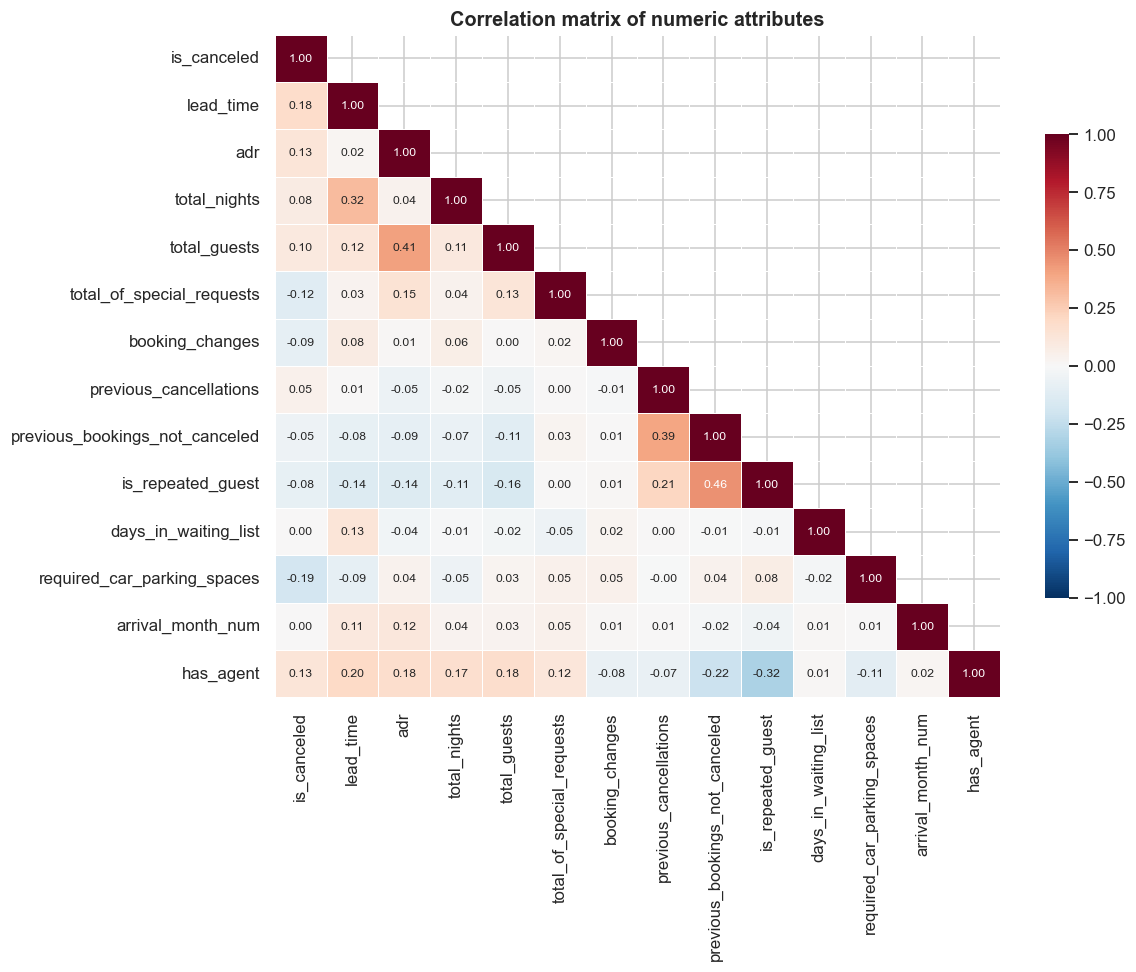

required_car_parking_spaces      -0.19
lead_time                         0.18
has_agent                         0.13
adr                               0.13
total_of_special_requests        -0.12
total_guests                      0.10
booking_changes                  -0.09
is_repeated_guest                -0.08
total_nights                      0.08
previous_bookings_not_canceled   -0.05
previous_cancellations            0.05
arrival_month_num                 0.00
days_in_waiting_list              0.00
Name: is_canceled, dtype: float64

In [15]:
corr_cols = ["is_canceled", "lead_time", "adr", "total_nights", "total_guests",
             "total_of_special_requests", "booking_changes", "previous_cancellations",
             "previous_bookings_not_canceled", "is_repeated_guest", "days_in_waiting_list",
             "required_car_parking_spaces", "arrival_month_num", "has_agent"]
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=0.5, annot_kws={"size": 8}, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Correlation matrix of numeric attributes")
fig.tight_layout()
save(fig, "eda_06_correlation_matrix")
plt.show()

corr["is_canceled"].drop("is_canceled").sort_values(key=abs, ascending=False).round(2)

## Figure for the report: class distribution and cancellation rate by lead time

This figure uses the final dataset after the outlier analysis (notebook 03).
It shows that the classes are imbalanced (72.3% / 27.7%) and that the cancellation rate
increases with lead time.

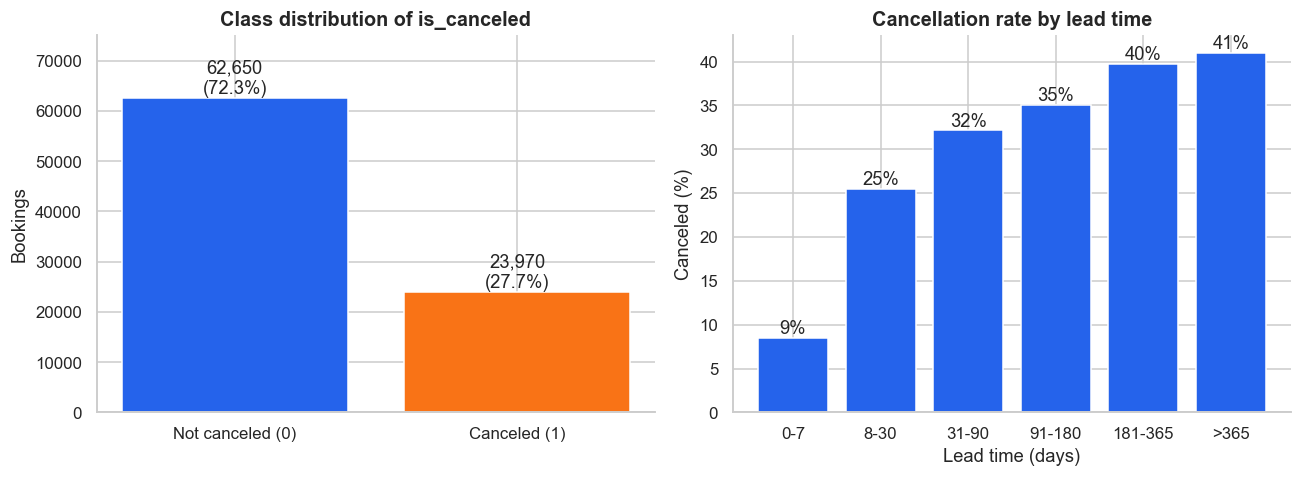

In [16]:
# Figure for the report: class distribution and cancellation rate by lead time
df_final = pd.read_csv("../data/processed/hotel_bookings_final.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

counts = df_final["is_canceled"].value_counts().sort_index()
axes[0].bar(["Not canceled (0)", "Canceled (1)"], counts.values, color=[BLUE, ORANGE])
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}\n({v / len(df_final):.1%})", ha="center", va="bottom")
axes[0].set_ylim(0, counts.max() * 1.2)
axes[0].set_title("Class distribution of is_canceled")
axes[0].set_ylabel("Bookings")

groups = pd.cut(df_final["lead_time"], [-1, 7, 30, 90, 180, 365, 1000],
                labels=["0-7", "8-30", "31-90", "91-180", "181-365", ">365"])
rate = df_final.groupby(groups, observed=True)["is_canceled"].mean()
axes[1].bar(rate.index.astype(str), rate.values * 100, color=BLUE)
for i, v in enumerate(rate.values):
    axes[1].text(i, v * 100, f"{v:.0%}", ha="center", va="bottom")
axes[1].set_title("Cancellation rate by lead time")
axes[1].set_xlabel("Lead time (days)")
axes[1].set_ylabel("Canceled (%)")

plt.tight_layout()
plt.savefig(FIG_DIR / "stat_01_class_leadtime.png", dpi=150, bbox_inches="tight")
plt.show()

ــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــ

## Summary of findings

**Typical booking** (median): booked **50 days** ahead, **€99** per night, **3 nights**.
Lead time is strongly right-skewed (mean 80 > median 50); 1,052 bookings are complimentary (ADR = 0).

**Attributes related to cancellation** (overall rate 27.7%):

| Attribute | Lowest group | Highest group |
| --- | --- | --- |
| Lead time | 0–7 days: 9% | over 365 days: 41% (rises steadily) |
| Market segment | Corporate: 12% | Online TA: 36% |
| Special requests | 3 or more: 16% | none: 33% |
| Previous cancellations | none: 27% | at least one: 68% (1,677 bookings) |
| Customer type | Group: 10% | Transient: 30% |
| Deposit type | No Deposit: 27% | Non Refund: 95% (only 1,037 bookings; correlation, not causation) |

**Seasonality:** prices at the Resort Hotel rise almost **4×** from January (€50) to August (€189), and its cancellation
rate rises with them (14% → 33%). The City Hotel is more stable (€86–128, cancellation 25–35%).
The effect of the month **depends on the hotel** (an interaction).

**Prices:** City Hotel median €106 with a narrow spread (IQR €49); Resort Hotel median €80 with a wide spread (IQR €83).
Both have many high values beyond the IQR whiskers, to be analysed in Outlier Detection.

**Relationships:** canceled and kept bookings overlap heavily on lead time vs. price, so cancellation cannot be predicted
from two attributes. Linear correlations with cancellation are all weak (|r| ≤ 0.19), and the strongest one
(`required_car_parking_spaces`) is data leakage. No pair of attributes is highly correlated (all |r| < 0.5).

### Implications for modelling

| Finding | Consequence |
| --- | --- |
| Clear differences in cancellation rate across lead time, segment, requests, customer type | Good candidate attributes for **classification** |
| Classes overlap; correlations weak | Expect moderate accuracy; compare against the 72% baseline, not 100% |
| Month effect differs by hotel | **Decision Tree Regression** should capture it better than Linear Regression |
| Lead time and nights are skewed | Use a log transform before distance-based methods (**KNN, K-Means**) |
| Many high prices beyond the IQR whiskers | Analyse with IQR, Z-Score and Isolation Forest in **Outlier Detection** |
| Parking and assigned room reveal the outcome | Exclude from classification (**leakage**) |
| No highly correlated pairs | No attributes need to be dropped for multicollinearity |

**Figures saved** in `figures/`: `eda_01` – `eda_06`.

**Next step:** `05_classification.ipynb`.